# Statistics and Trends: Exploring a Diabetes Dataset

**Student:** Vamsee Mandla  
**Student number:** 25109128

## Project aim
This notebook explores the Scikit-learn diabetes dataset containing 442 records. It examines the distribution of the one-year disease progression measure, the relationship between BMI and progression, differences between four sample-based BMI groups, and correlations among the numerical variables.

> **Important:** This is an educational dataset for statistical exploration. It must not be used to make medical diagnoses or treatment decisions. The BMI feature is standardised, so its values are not raw BMI measurements in kg/m².

## 1. Import the required libraries

The notebook uses pandas for data handling, NumPy for numerical calculations, and Matplotlib/Seaborn for visualisations.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

%matplotlib inline
sns.set_theme(style="white")

# Use the CSV placed in the same folder as this notebook.
DATA_FILE = Path("diabetes_dataset.csv")
df = pd.read_csv(DATA_FILE)

print("Dataset loaded successfully.")
print("Shape:", df.shape)

Dataset loaded successfully.
Shape: (442, 11)


## 2. Understand the dataset

Display the first few records, column names, data types, and missing-value counts.

In [2]:
display(df.head(10))
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types and non-null counts:")
df.info()

print("\nMissing values in each column:")
display(df.isnull().sum().to_frame("Missing values"))

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,progression
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0
5,-0.092695,-0.044642,-0.040696,-0.019442,-0.068991,-0.079288,0.041277,-0.076395,-0.041176,-0.096346,97.0
6,-0.045472,0.050680,-0.047163,-0.015999,-0.040096,-0.024800,0.000779,-0.039493,-0.062917,-0.038357,138.0
7,0.063504,0.050680,-0.001895,0.066629,0.090620,0.108914,0.022869,0.017703,-0.035816,0.003064,63.0
8,0.041708,0.050680,0.061696,-0.040099,-0.013953,0.006202,-0.028674,-0.002592,-0.014960,0.011349,110.0
9,-0.070900,-0.044642,0.039062,-0.033213,-0.012577,-0.034508,-0.024993,-0.002592,0.067737,-0.013504,310.0



Column names:
['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6', 'progression']

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   age          442 non-null    float64
 1   sex          442 non-null    float64
 2   bmi          442 non-null    float64
 3   bp           442 non-null    float64
 4   s1           442 non-null    float64
 5   s2           442 non-null    float64
 6   s3           442 non-null    float64
 7   s4           442 non-null    float64
 8   s5           442 non-null    float64
 9   s6           442 non-null    float64
 10  progression  442 non-null    float64
dtypes: float64(11)
memory usage: 38.1 KB

Missing values in each column:


,Missing values
age,0
sex,0
bmi,0
bp,0
s1,0
s2,0
s3,0
s4,0
s5,0
s6,0


## 3. Descriptive statistics

The target column `progression` represents the quantitative one-year disease progression measure. Calculate its mean, median, standard deviation, minimum, and maximum.

In [3]:
target = df["progression"]

summary = pd.Series({
    "Mean": target.mean(),
    "Median": target.median(),
    "Standard deviation": target.std(),
    "Minimum": target.min(),
    "Maximum": target.max()
})

display(summary.to_frame("Progression measure").round(2))
print(f"Number of records: {len(df)}")

,Progression measure
Mean,152.13
Median,140.50
Standard deviation,77.09
Minimum,25.00
Maximum,346.00


Number of records: 442


## 4. Figure 1 — Distribution of the outcome measure

The histogram shows how the progression scores are distributed. The dashed vertical line represents the mean and the dotted vertical line represents the median.

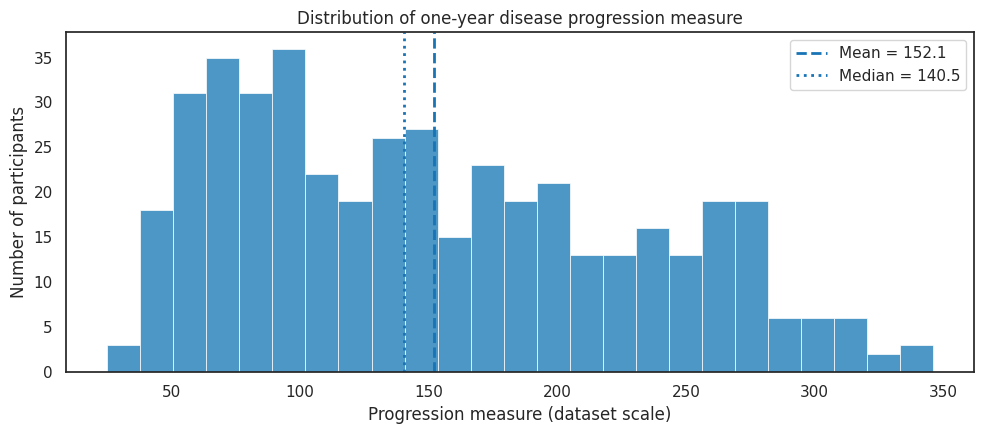

In [4]:
mean_value = target.mean()
median_value = target.median()

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.hist(target, bins=25, color="#4C97C5", edgecolor="white", linewidth=0.5)
ax.axvline(mean_value, color="#1874B5", linestyle="--", linewidth=2,
           label=f"Mean = {mean_value:.1f}")
ax.axvline(median_value, color="#1874B5", linestyle=":", linewidth=2,
           label=f"Median = {median_value:.1f}")
ax.set_title("Distribution of one-year disease progression measure")
ax.set_xlabel("Progression measure (dataset scale)")
ax.set_ylabel("Number of participants")
ax.legend()
fig.tight_layout()
plt.show()

## 5. Figure 2 — BMI and the outcome measure

A scatter plot is used to explore the relationship between BMI and progression. The straight line is a least-squares trend line. Pearson correlation is also calculated.

A positive correlation indicates an association in this sample; it does not prove that BMI causes a change in progression.

Pearson correlation between BMI and progression: 0.59


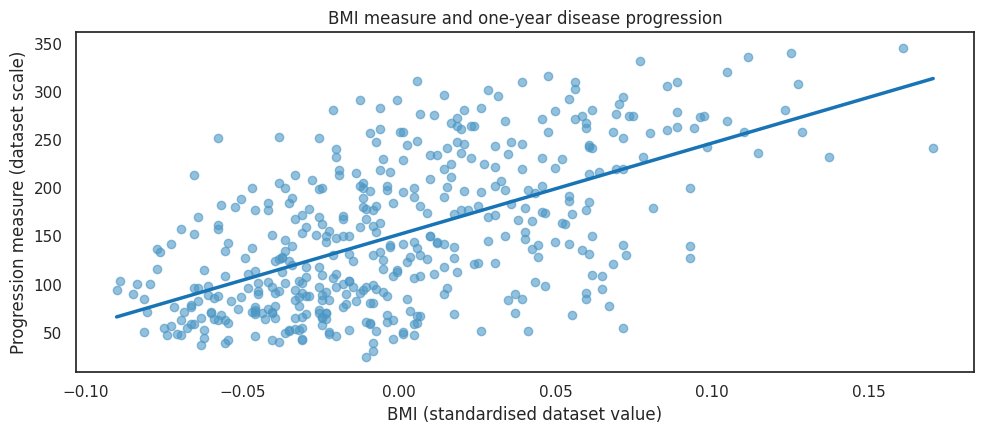

In [5]:
bmi = df["bmi"]
correlation = bmi.corr(target)
print(f"Pearson correlation between BMI and progression: {correlation:.2f}")

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.scatter(bmi, target, alpha=0.6, color="#4C97C5")
slope, intercept = np.polyfit(bmi, target, 1)
x_line = np.linspace(bmi.min(), bmi.max(), 200)
ax.plot(x_line, slope * x_line + intercept, color="#1874B5", linewidth=2.5)
ax.set_title("BMI measure and one-year disease progression")
ax.set_xlabel("BMI (standardised dataset value)")
ax.set_ylabel("Progression measure (dataset scale)")
fig.tight_layout()
plt.show()

## 6. Figure 3 — Compare progression across BMI groups

Participants are divided into four groups based on their BMI values in this sample. These are sample quartiles, not official medical BMI categories. The box plot compares the distribution of progression scores in each group.

/tmp/ipykernel_1196/1431187197.py:15: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(box_data, labels=group_order)


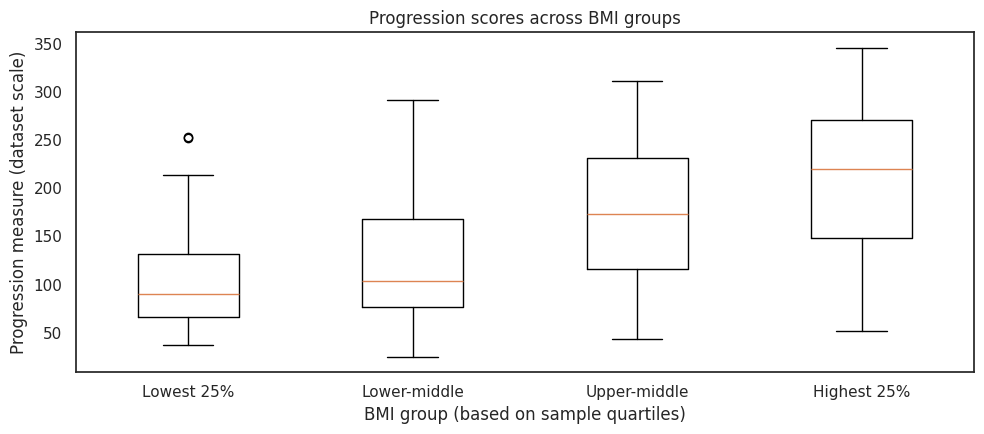

,count,mean,median,std
BMI group,,,,
Lowest 25%,111,102.94,90.0,48.95
Lower-middle,110,123.74,104.0,61.24
Upper-middle,110,171.67,173.5,71.84
Highest 25%,111,210.11,220.0,74.70


In [6]:
df_plot = df.copy()
df_plot["BMI group"] = pd.qcut(
    df_plot["bmi"].rank(method="first"),
    q=4,
    labels=["Lowest 25%", "Lower-middle", "Upper-middle", "Highest 25%"]
)

group_order = ["Lowest 25%", "Lower-middle", "Upper-middle", "Highest 25%"]
box_data = [
    df_plot.loc[df_plot["BMI group"] == group, "progression"].to_numpy()
    for group in group_order
]

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.boxplot(box_data, labels=group_order)
ax.set_title("Progression scores across BMI groups")
ax.set_xlabel("BMI group (based on sample quartiles)")
ax.set_ylabel("Progression measure (dataset scale)")
fig.tight_layout()
plt.show()

group_summary = df_plot.groupby("BMI group", observed=False)["progression"].agg(
    ["count", "mean", "median", "std"]
)
display(group_summary.round(2))

## 7. Correlation heatmap

The heatmap displays Pearson correlations between the numerical variables. Values closer to +1 indicate a stronger positive linear relationship, while values closer to -1 indicate a stronger negative linear relationship. Correlation does not establish causation.

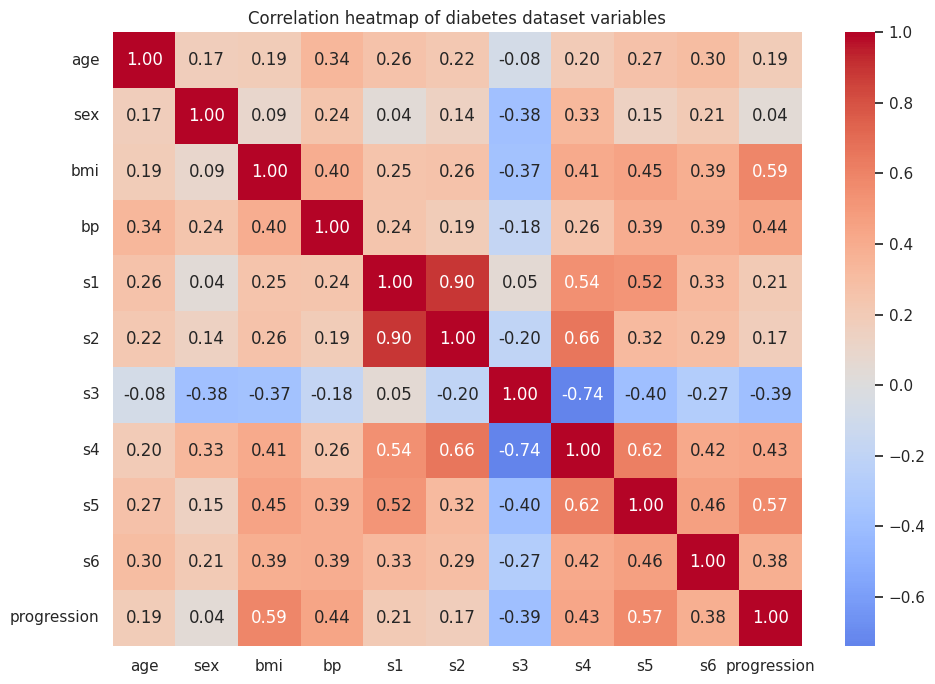

In [7]:
correlation_matrix = df.corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(10, 7))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f",
    ax=ax
)
ax.set_title("Correlation heatmap of diabetes dataset variables")
fig.tight_layout()
plt.show()

## 8. Key findings

Use the values printed by the notebook when writing your final interpretation. With the supplied 442-record dataset, the target mean is approximately **152.1**, the median is **140.5**, the standard deviation is **77.1**, and the BMI/progression Pearson correlation is approximately **0.59**.

The results suggest a moderate positive association between BMI and the progression measure. The four BMI-group box plots can be used to compare medians and spread. There is overlap between groups, so BMI alone does not explain all variation in progression.

## 9. Limitations

- The dataset contains 442 records and should not be treated as representative of every population.
- BMI is standardised in this dataset; it is not expressed in kg/m².
- The analysis is observational and shows associations, not cause-and-effect relationships.
- The results are for learning and statistical exploration only, not clinical decision-making.

## 10. Dataset download

The CSV file used by this notebook is named `diabetes_dataset.csv` and should remain in the same folder as this notebook.